# 09c — Target, Follow-up, Predictor Coverage, and Review Objectives

Audit the causes of weak minority detection before adding another model family. Reusable code lives in `Python/target_predictor_audit.py`. This notebook implements label/follow-up checks, a complete column inventory, controlled predictor scenarios, and class-specific operating-point evaluation.

**Preserve** the required three-class target, cohorts, chronological cutoffs, and earlier results. No test rows are read. Prior validation findings motivated the audit, so subsequent validation results are development comparisons, not an unbiased final test. New model/scenario and threshold choices use training CV only.

Prediction point remains **after pricing at origination** for classification. Grade/subgrade are not introduced into pre-pricing rate regression. Audit-only event dates, scheduled maturity, Current exclusions, and loan status are never predictors.

In [1]:
import sys, json, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import precision_recall_curve, average_precision_score
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from Python.target_predictor_audit import (AuditConfig, TargetPredictorAudit,
    PredictorAuditExperiment, ISSUER_SOURCE, BUREAU_COLUMNS, PRICING_COLUMNS)
OUT = PROJECT_ROOT / 'outputs' / 'target_predictor_audit'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
config = AuditConfig()
audit = TargetPredictorAudit(PROJECT_ROOT, OUT, config)
experiment = PredictorAuditExperiment(PROJECT_ROOT, OUT, config)
metadata = {'configuration': config.to_dict(), 'split': experiment.setup.split_config,
            'python': platform.python_version(), 'numpy': np.__version__, 'sklearn': sklearn.__version__,
            'prediction_time': 'After-pricing origination classifier; never pre-pricing regression',
            'evidence': {'project': 'Project.pdf: task-dependent grade/subgrade eligibility and baseline-bureau rules',
                         'issuer': ISSUER_SOURCE,
                         'issuer_scope': '2012 issuer underwriting/pricing description; not a timestamp certificate for every 2007–2018 record'},
            'bureau_scenario': 'Conditional on fields representing original bureau snapshot; deferred fields remain unused',
            'selection': 'Training-CV average precision separately for At risk and Default',
            'operating_points': 'Analytic precision floors only, minimum 20 alerts in every CV fold; not an approved lending policy',
            'test_policy': 'No final test rows read; prior results and predictor plan unchanged'}
_ = (OUT / 'experiment_config.json').write_text(json.dumps(metadata, indent=2))
display(pd.Series(config.to_dict(), name='setting').to_frame())

,setting
variants,"(current, pricing_grade, pricing_bureau)"
families,"(logistic, boosting)"
seed,42
threads,2
precision_floors,"(0.05, 0.1, 0.2)"
minimum_alerts_per_fold,20
review_fractions,"(0.01, 0.05)"
cutoff_scenarios,"(2018-12-31, 2019-12-31)"


## 1. Audit labels, loan term, exclusions, and observation metadata

Read development loans from the processed accepted regression cohort, which retains Current and other statuses excluded from classification. That source requires a non-null interest rate; verify that all known classification outcomes match the frozen classification cohort counts. Report every source status in the audit denominators rather than pretending that excluded Current loans have known outcomes.

Cross-tabulate status by origination month/year and 36/60-month term. Compare eligibility/exclusion rates across vintages. Compute initial scheduled maturity as origination month plus recorded term **for auditing only**. Early repayment, modification, and extended collection periods mean scheduled maturity is not the actual outcome date.

The December 2018 and December 2019 dates below are **hypothetical sensitivity scenarios**, not inferred extraction dates. A filename, file timestamp, latest payment date, or latest scheduled maturity cannot establish a common observation cutoff for all labels. Do not filter the modelling cohort or claim a historical backtest from these scenarios.

,partition,term,Good,At risk,Default
0,train,36.0,291735,0,43823
1,train,60.0,82825,611,32677
2,validation,36.0,427135,4586,88252
3,validation,60.0,97460,4905,55804


,partition,year,term,source_n,eligible_n,excluded_share
0,train,2007,36.0,603,251,0.583748
1,train,2008,36.0,2393,1562,0.347263
2,train,2009,36.0,5281,4716,0.106987
3,train,2010,36.0,9156,8466,0.07536
4,train,2010,60.0,3381,3070,0.091985
5,train,2011,36.0,14101,14101,0.0
6,train,2011,60.0,7620,7620,0.0
7,train,2012,36.0,43470,43470,0.0
8,train,2012,60.0,9897,9897,0.0
9,train,2013,36.0,100422,100422,0.0


,field,n_observed,earliest,latest,role
0,last_pymnt_d,1320660,2007-12-01 00:00:00,2019-03-01 00:00:00,audit only; not observation cutoff
1,last_credit_pull_d,1321787,2007-05-01 00:00:00,2019-04-01 00:00:00,audit only; not observation cutoff
2,next_pymnt_d,202148,2008-01-01 00:00:00,2019-05-01 00:00:00,audit only; not observation cutoff


confirmed_common_observation_cutoff                                                           None
missing_observation_metadata                     [snapshot_date, observation_date, loan_status_...
scheduled_maturity_is_not_actual_outcome_time                                                 True
note                                             Scenarios are hypothetical, not inferred extra...
historical_backtest_supported                                                                False
target_and_cohorts_changed                                                                   False
audit_source                                     accepted_regression_fe development rows with n...
Name: conclusion, dtype: object

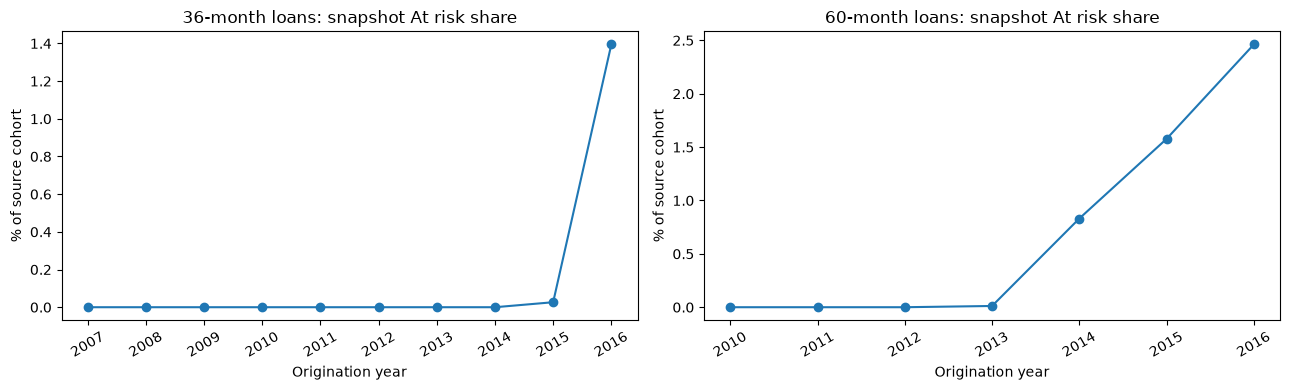

,partition,term,loan_status,n,share_scheduled_term_elapsed,hypothetical_cutoff
0,train,36.0,Charged Off,43823,1.000000,2018-12-31
1,train,36.0,Does not meet the credit policy. Status:Charge...,649,1.000000,2018-12-31
2,train,36.0,Does not meet the credit policy. Status:Fully ...,1789,1.000000,2018-12-31
3,train,36.0,Fully Paid,291735,1.000000,2018-12-31
4,train,60.0,Charged Off,32676,0.423246,2018-12-31
5,train,60.0,Current,11925,0.000503,2018-12-31
6,train,60.0,Default,1,0.000000,2018-12-31
7,train,60.0,Does not meet the credit policy. Status:Charge...,112,1.000000,2018-12-31
8,train,60.0,Does not meet the credit policy. Status:Fully ...,199,1.000000,2018-12-31
9,train,60.0,Fully Paid,82825,0.496698,2018-12-31


In [1]:
term_counts, eligibility, followup = audit.run()
display(term_counts)
display(eligibility)
display(pd.read_csv(OUT / 'event_date_audit.csv'))
display(pd.Series(followup, name='conclusion'))
assert followup['confirmed_common_observation_cutoff'] is None
status = pd.read_csv(OUT / 'status_year_term.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, term in zip(axes, [36, 60]):
    frame = status[(status.term == term) & status.loan_status.isin(['Late (16-30 days)', 'Late (31-120 days)', 'In Grace Period'])]
    years = sorted(status.loc[status.term == term, 'year'].unique())
    series = frame.groupby('year').share_of_source_cohort.sum().reindex(years, fill_value=0.)
    ax.plot(series.index, series.values * 100, marker='o')
    ax.set_xticks(years, [str(year) for year in years], rotation=30)
    ax.set(title=f'{term}-month loans: snapshot At risk share', xlabel='Origination year', ylabel='% of source cohort')
fig.tight_layout()
fig.savefig(FIG / 'at_risk_vintage_term.png', dpi=150)
plt.show()
display(pd.read_csv(OUT / 'maturity_scenarios.csv'))

## 2. Inventory every field and inspect vintage missingness

The full inventory distinguishes existing inputs, new pricing scenarios, conditional bureau scenarios, audit/target-only fields, explicit post-origination leakage, and fields deferred for insufficient availability evidence. A name containing delinquency or collections does not automatically establish leakage; nor does a plausible name prove baseline availability.

**Defensible pricing scenario:** `grade` and `sub_grade` are explicitly permitted by Project.pdf for this after-pricing classifier. LendingClub's [issuer prospectus](https://www.sec.gov/Archives/edgar/data/1409970/000119312512325943/d353028d424b3.htm) describes assigning grades to loan requests before pricing/posting/origination. Their original assigned values are assumed to be retained in the supplied data. They remain banned for pre-pricing regression.

**Conditional bureau scenario:** test `tax_liens`, `collections_12_mths_ex_med`, and `acc_now_delinq` separately on top of grades. The same issuer document describes obtaining applicant credit reports and considering tax liens, nonmedical collections within twelve months, and current delinquencies. Project.pdf permits prior-bureau history when verified. Mapping these aggregate fields to the original application report is an explicit research assumption: the source does not certify every record's timestamp or prove that no value was refreshed. This scenario must not be promoted to deployment without that provenance. Other omitted bureau/process/text fields remain deferred.

Inspect missingness by origination year and application type. Missing secondary-applicant information for Individual applications is not zero-valued credit history. No new joint-field zero filling or additional post-event features are introduced.

,n_columns
decision,
conditional_bureau_scenario,3
deferred_not_verified,72
excluded_administrative,6
excluded_post_origination,37
existing_input,44
new_pricing_scenario,2
split_audit_only,1
target_only,2


,column,decision,reason,source,evidence_url
3,funded_amnt,deferred_not_verified,No new use without a documented definition and...,Existing project plan/schema,
4,funded_amnt_inv,deferred_not_verified,No new use without a documented definition and...,Existing project plan/schema,
8,grade,new_pricing_scenario,Project explicitly permits original assigned g...,Project.pdf; issuer prospectus,https://www.sec.gov/Archives/edgar/data/140997...
9,sub_grade,new_pricing_scenario,Project explicitly permits original assigned g...,Project.pdf; issuer prospectus,https://www.sec.gov/Archives/edgar/data/140997...
10,emp_title,deferred_not_verified,No new use without a documented definition and...,Existing project plan/schema,
...,...,...,...,...,...
124,sec_app_num_rev_accts,deferred_not_verified,No new use without a documented definition and...,Existing project plan/schema,
125,sec_app_chargeoff_within_12_mths,deferred_not_verified,No new use without a documented definition and...,Existing project plan/schema,
126,sec_app_collections_12_mths_ex_med,deferred_not_verified,No new use without a documented definition and...,Existing project plan/schema,
127,sec_app_mths_since_last_major_derog,deferred_not_verified,No new use without a documented definition and...,Existing project plan/schema,


,partition,year,column,n,missing_share
0,train,2007,acc_now_delinq,251,0.000000
9,train,2007,collections_12_mths_ex_med,251,0.223108
19,train,2007,grade,251,0.000000
43,train,2007,sub_grade,251,0.000000
44,train,2007,tax_liens,251,0.155378
52,train,2008,acc_now_delinq,1562,0.000000
61,train,2008,collections_12_mths_ex_med,1562,0.000000
71,train,2008,grade,1562,0.000000
95,train,2008,sub_grade,1562,0.000000
96,train,2008,tax_liens,1562,0.000000


,partition,application_type,field,n,missing_share
0,train,Individual,annual_inc_joint,451671,1.000000
1,train,Individual,dti_joint,451671,1.000000
2,train,Individual,sec_app_fico_range_low,451671,1.000000
3,validation,Individual,annual_inc_joint,672231,1.000000
4,validation,Individual,dti_joint,672231,1.000000
5,validation,Individual,sec_app_fico_range_low,672231,1.000000
6,validation,Joint App,annual_inc_joint,5911,0.000000
7,validation,Joint App,dti_joint,5911,0.000508
8,validation,Joint App,sec_app_fico_range_low,5911,1.000000


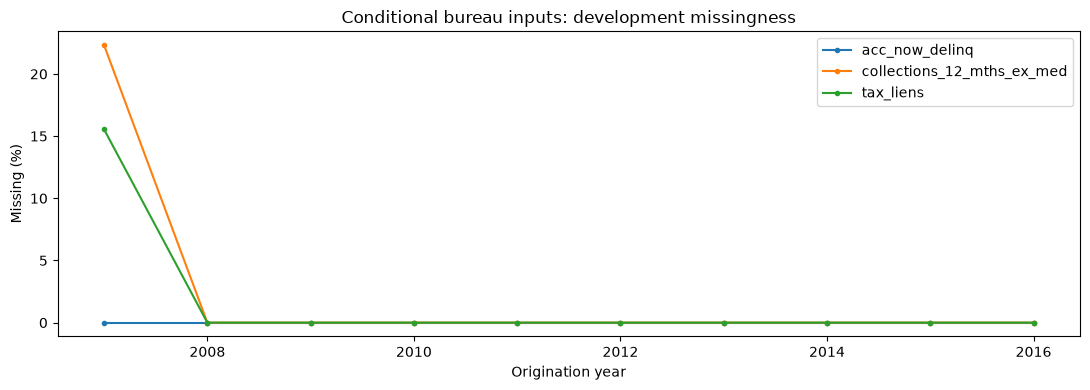

In [3]:
inventory = audit.inventory()
display(inventory.groupby('decision').size().rename('n_columns').to_frame())
display(inventory[inventory.decision.isin(['new_pricing_scenario', 'conditional_bureau_scenario', 'deferred_not_verified'])])
missing = pd.read_csv(OUT / 'predictor_missingness_vintage.csv')
display(missing[missing.column.isin(list(PRICING_COLUMNS) + list(BUREAU_COLUMNS))])
display(pd.read_csv(OUT / 'joint_nonapplicability.csv'))
fig, ax = plt.subplots(figsize=(11, 4))
for name, frame in missing[missing.column.isin(BUREAU_COLUMNS)].groupby('column'):
    ax.plot(frame.year, frame.missing_share * 100, marker='.', label=name)
ax.set(title='Conditional bureau inputs: development missingness', xlabel='Origination year', ylabel='Missing (%)')
ax.legend()
fig.tight_layout()
fig.savefig(FIG / 'candidate_missingness.png', dpi=150)
plt.show()

## 3. Strengthen the explicit leakage guard

The existing allowlists already excluded the following fields, so earlier estimator inputs and scores are unchanged. The general leakage list now also explicitly excludes the real source alias `last_pymnt_amnt` and hardship auxiliaries `deferral_term`, `payment_plan_start_date`, and `orig_projected_additional_accrued_interest`. This closes a guard-coverage gap before future feature experiments. Existing tests plus a focused regression test verify these exclusions.

## 4. Controlled predictor experiment and class-specific objectives

Compare three declared scenarios: **current**, **current + grade/subgrade**, and **pricing + three conditional bureau counts**. Keep the earlier imputation/scaling/one-hot pipeline, complete training folds, and balanced class weights constant. No additional sampling or robust-transform change is made here, so predictor-group effects are not confounded with another treatment revision.

Use fixed C=1 logistic regression (Newton-CG, max 200 iterations, tolerance 0.001) and fixed histogram boosting (100 iterations, learning rate 0.1, 31 leaves, minimum leaf size 100, L2=1, no random early stopping). Fit 3 scenarios × 2 models × 5 chronological folds = **30 CV fits**, plus **six full-training fits**. Two native threads; one fixed seed. These are limited predictor ablations, not a new hyperparameter search.

Select a model/scenario **separately for At risk review and Default review**, maximizing mean fold average precision for that class. Macro F1 and default argmax remain reported, but no longer decide the review objective. Selection occurs before validation scoring. Selecting among these candidates induces optimism in CV scores; the validation period has already informed earlier development.

**Operating points:** precision floors of 5%, 10%, and 20% are illustrative diagnostic constraints, not user-approved costs. Select the highest mean fold recall subject to the floor and at least 20 alerts in **every** CV fold. Search a declared set of low-to-high score cutoffs and quantiles computed from training out-of-fold scores. If no cutoff qualifies, mark the target infeasible; do not loosen it after seeing validation. Out-of-fold labels select the rule, so this is not unbiased nested-CV operating-point estimation.

At risk and Default flags are independent review queues and may overlap. They are not a relabelled or merged three-class outcome. Also report fixed 1% and 5% review budgets, using seeded outcome-independent tie breaking, without tuning against validation labels. Weighted model scores are not automatically calibrated population probabilities.

In [4]:
plan = []
for variant in config.variants:
    numeric, categorical = experiment.columns(variant)
    plan.append({'variant': variant, 'numeric': len(numeric), 'categorical': len(categorical),
                 'added_numeric': ', '.join(c for c in numeric if c not in experiment.setup.predictor_plan['classification']['numeric']),
                 'added_categorical': ', '.join(c for c in categorical if c not in experiment.setup.predictor_plan['classification']['categorical'])})
manifest = pd.DataFrame(plan)
manifest.to_csv(OUT / 'predictor_scenarios.csv', index=False)
display(manifest)
cv_scores, validation_scores = experiment.run()
display(pd.read_csv(OUT / 'cv_summary.csv'))
display(json.loads((OUT / 'goal_selections.json').read_text()))
display(json.loads((OUT / 'execution_summary.json').read_text()))

,variant,numeric,categorical,added_numeric,added_categorical
0,current,39,5,,
1,pricing_grade,39,7,,"grade, sub_grade"
2,pricing_bureau,42,7,"tax_liens, collections_12_mths_ex_med, acc_now...","grade, sub_grade"


current/logistic: CV fold 1, risk AP=0.0109


current/boosting: CV fold 1, risk AP=0.0102


current/logistic: CV fold 2, risk AP=0.0108


current/boosting: CV fold 2, risk AP=0.0098


current/logistic: CV fold 3, risk AP=0.0134


... (30 outputs left out)

pricing_bureau/boosting: full validation and artifact checks complete


,family,variant,risk_ap,risk_ap_fold_std,default_ap,default_ap_fold_std,macro_f1
0,boosting,current,0.013573,0.004230,0.340841,0.009780,0.396732
1,boosting,pricing_bureau,0.013453,0.004846,0.340342,0.011622,0.393458
2,boosting,pricing_grade,0.013478,0.004603,0.340954,0.010718,0.393714
3,logistic,current,0.014860,0.005727,0.251130,0.018016,0.353805
4,logistic,pricing_bureau,0.014240,0.005347,0.254347,0.027833,0.348689
5,logistic,pricing_grade,0.014361,0.005118,0.253611,0.026793,0.348004


{'source': 'Training CV average precision, separately for each review goal',
 'choices': {'At risk': {'family': 'logistic',
   'variant': 'current',
   'cv_average_precision': 0.014860366220873843},
  'Default': {'family': 'boosting',
   'variant': 'pricing_grade',
   'cv_average_precision': 0.3409538305730261}}}

{'seconds': 888.7162018329982}

## 5. Predictor effects: ranking and multiclass decisions

All external scores use the unchanged complete validation cohort. Gains in average precision concern ranking; gains in macro F1 concern a particular three-class decision rule. They can move differently. Compare scenarios within each model on identical rows. Conditional-scenario gains cannot certify the missing source provenance.

,family,variant,n_train,n_evaluation,n_features,f1_macro,ap_class_1,precision_class_1,recall_class_1,ap_class_2,precision_class_2,recall_class_2
0,logistic,current,451671,678142,113,0.377292,0.031676,0.032211,0.459277,0.287240,0.326192,0.305659
1,boosting,current,451671,678142,113,0.421880,0.028416,0.037509,0.099252,0.373045,0.357406,0.550230
2,logistic,pricing_grade,451671,678142,155,0.371847,0.026597,0.030424,0.418712,0.286765,0.305541,0.392188
3,boosting,pricing_grade,451671,678142,155,0.418938,0.027694,0.035386,0.099041,0.370256,0.353159,0.555305
4,logistic,pricing_bureau,451671,678142,158,0.371834,0.026557,0.030429,0.418712,0.287080,0.305450,0.392715
5,boosting,pricing_bureau,451671,678142,158,0.418557,0.027339,0.034628,0.102834,0.369463,0.353496,0.551431


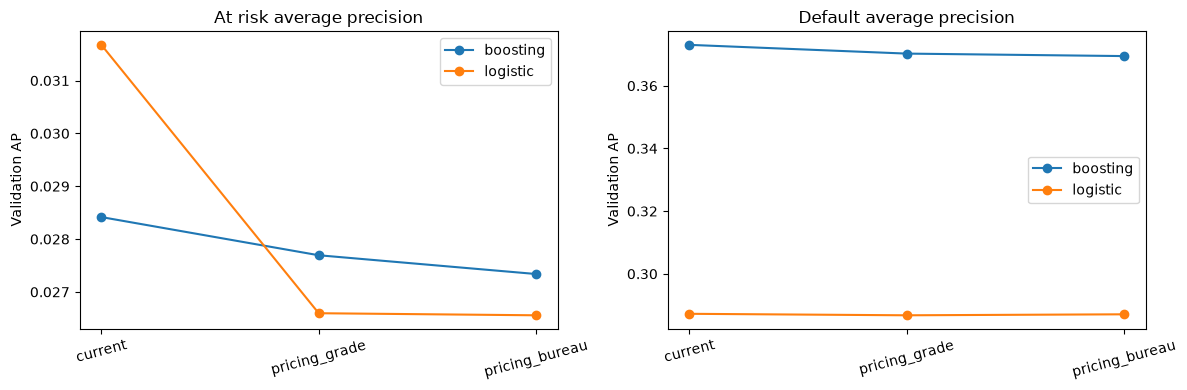

In [5]:
display(validation_scores[['family', 'variant', 'n_train', 'n_evaluation', 'n_features', 'f1_macro',
                           'ap_class_1', 'precision_class_1', 'recall_class_1', 'ap_class_2',
                           'precision_class_2', 'recall_class_2']])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in [(axes[0], 'ap_class_1', 'At risk average precision'),
                          (axes[1], 'ap_class_2', 'Default average precision')]:
    for family, frame in validation_scores.groupby('family'):
        frame = frame.set_index('variant').loc[list(config.variants)]
        ax.plot(range(len(frame)), frame[metric], marker='o', label=family)
    ax.set_xticks(range(3), config.variants, rotation=15)
    ax.set(title=title, ylabel='Validation AP')
    ax.legend()
fig.tight_layout()
fig.savefig(FIG / 'predictor_ap_comparison.png', dpi=150)
plt.show()

## 6. Precision–recall curves on the same validation population

Each panel compares declared scenarios within the same family and class. The horizontal reference is that class's validation prevalence. Do not compare raw precision/AP across different-prevalence populations as though they shared the same baseline. CV class priors differ from validation, so a threshold meeting an earlier precision target may not transfer.

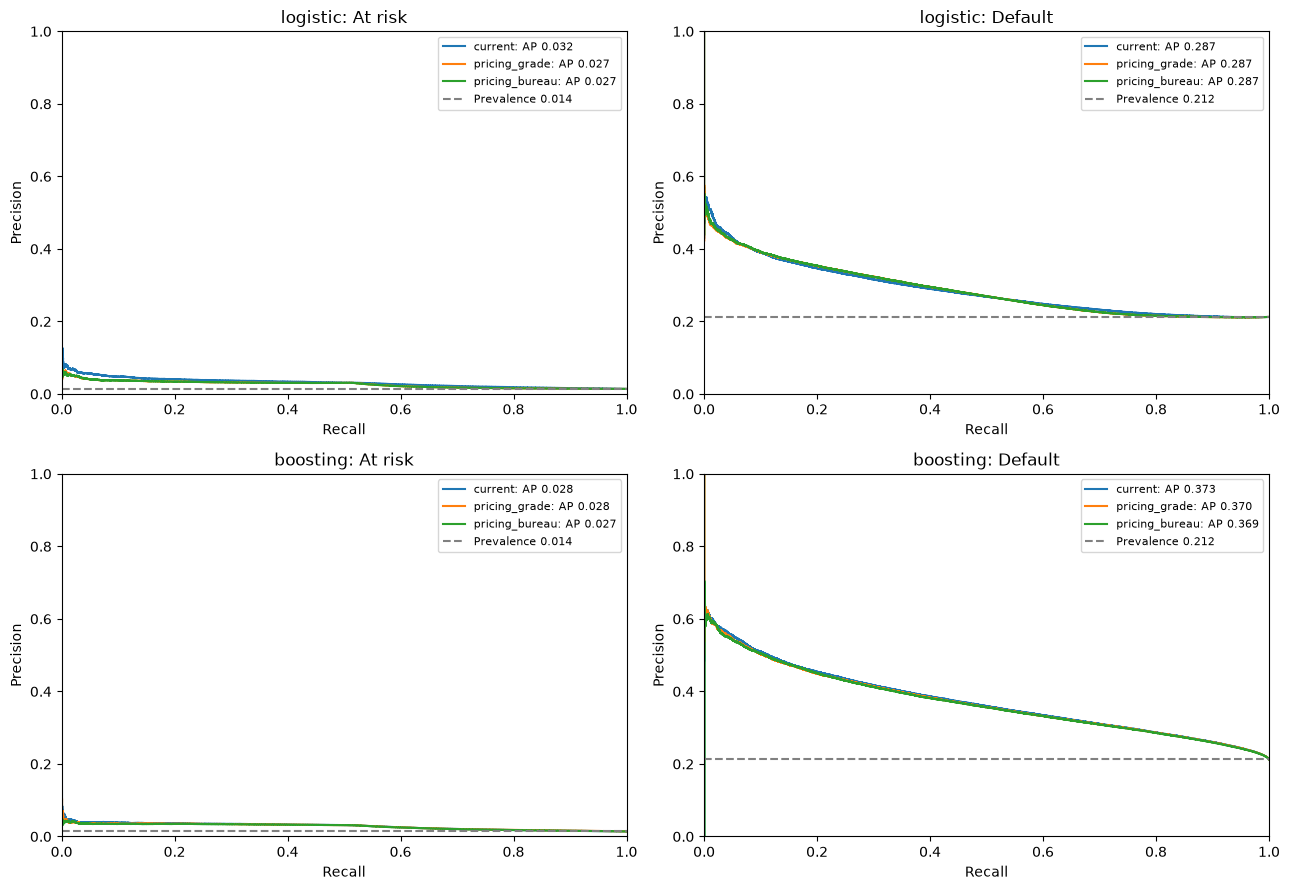

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
curve_rows = []
for row, family in enumerate(config.families):
    for col, label in enumerate([1, 2]):
        ax = axes[row, col]
        for variant in config.variants:
            frame = pd.read_parquet(OUT / f'{family}_{variant}_validation_predictions.parquet')
            y, probability = frame.target_class.eq(label), frame[f'probability_{label}']
            precision, recall, threshold = precision_recall_curve(y, probability)
            ap = average_precision_score(y, probability)
            ax.plot(recall, precision, label=f'{variant}: AP {ap:.3f}')
            # Persist the curve for reproducible plotting without fitting models.
            pd.DataFrame({'precision': precision, 'recall': recall,
                          'threshold': np.r_[threshold, np.nan]}).to_parquet(
                OUT / f'{family}_{variant}_class_{label}_pr_curve.parquet', index=False)
        ax.axhline(y.mean(), color='gray', linestyle='--', label=f'Prevalence {y.mean():.3f}')
        ax.set(title=f'{family}: {"At risk" if label == 1 else "Default"}', xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1))
        ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'precision_recall_curves.png', dpi=150)
plt.show()

## 7. Can training-CV precision constraints be met, and do they transfer?

An infeasible target is a result, not a reason to inspect validation for a replacement threshold. Tables report whether a feasible CV rule still meets its floor in validation, together with its alert count and recall. Independent class-specific flags do not alter the stored multiclass predictions.

### At risk: CV-selected ranking model {'family': 'logistic', 'variant': 'current', 'cv_average_precision': 0.014860366220873843}

,label,precision_floor,feasible,threshold,family,variant,alerts,true_positives,precision,recall,alert_share,minimum_fold_precision,minimum_fold_alerts,mean_fold_recall
0,1,0.05,False,NaN,logistic,current,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,0.10,False,NaN,logistic,current,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,0.20,False,NaN,logistic,current,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,family,variant,label,precision_floor,cv_feasible,threshold,alerts,true_positives,precision,recall,alert_share,validation_floor_met
0,logistic,current,1,0.05,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,logistic,current,1,0.10,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,logistic,current,1,0.20,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Default: CV-selected ranking model {'family': 'boosting', 'variant': 'pricing_grade', 'cv_average_precision': 0.3409538305730261}

,label,precision_floor,feasible,threshold,family,variant,alerts,true_positives,precision,recall,alert_share,minimum_fold_precision,minimum_fold_alerts,mean_fold_recall
21,2,0.05,True,0.05,boosting,pricing_grade,192705.0,36160.0,0.187644,1.000000,0.999186,0.176307,32438.0,1.000000
22,2,0.10,True,0.05,boosting,pricing_grade,192705.0,36160.0,0.187644,1.000000,0.999186,0.176307,32438.0,1.000000
23,2,0.20,True,0.30,boosting,pricing_grade,144574.0,32956.0,0.227952,0.911394,0.749624,0.208964,23198.0,0.911196


,family,variant,label,precision_floor,cv_feasible,threshold,alerts,true_positives,precision,recall,alert_share,validation_floor_met
21,boosting,pricing_grade,2,0.05,True,0.05,677893.0,144055.0,0.212504,0.999993,0.999633,True
22,boosting,pricing_grade,2,0.10,True,0.05,677893.0,144055.0,0.212504,0.999993,0.999633,True
23,boosting,pricing_grade,2,0.20,True,0.30,464914.0,125079.0,0.269037,0.868267,0.685570,True


,family,variant,label,fraction,alerts,true_positives,precision,recall,prevalence,precision_lift
0,logistic,current,1,0.01,6782,390,0.057505,0.041092,0.013996,4.108805
1,logistic,current,1,0.05,33908,1445,0.042615,0.152249,0.013996,3.044909
2,logistic,current,2,0.01,6782,3159,0.465792,0.021929,0.212427,2.192710
3,logistic,current,2,0.05,33908,13365,0.394155,0.092776,0.212427,1.855479
4,boosting,current,1,0.01,6782,271,0.039959,0.028553,0.013996,2.855092
5,boosting,current,1,0.05,33908,1277,0.037661,0.134549,0.013996,2.690899
6,boosting,current,2,0.01,6782,3919,0.577853,0.027205,0.212427,2.720237
7,boosting,current,2,0.05,33908,16859,0.497198,0.117031,0.212427,2.340555
8,logistic,pricing_grade,1,0.01,6782,308,0.045414,0.032452,0.013996,3.244902
9,logistic,pricing_grade,1,0.05,33908,1241,0.036599,0.130755,0.013996,2.615040


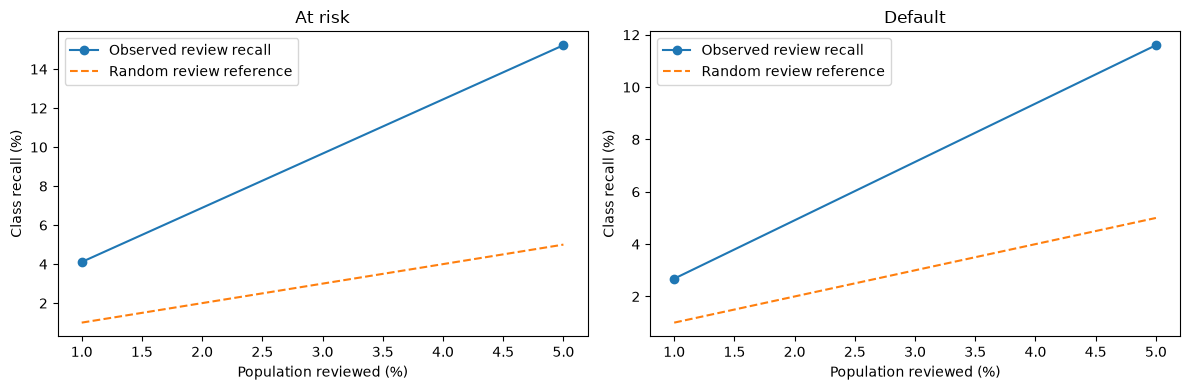

In [7]:
operating = pd.read_csv(OUT / 'validation_operating_points.csv')
cv_operating = pd.read_csv(OUT / 'cv_operating_points.csv')
choices = json.loads((OUT / 'goal_selections.json').read_text())['choices']
selected_rows = []
for name, label in [('At risk', 1), ('Default', 2)]:
    choice = choices[name]
    selected = operating[(operating.family == choice['family']) & (operating.variant == choice['variant']) & (operating.label == label)]
    selected_rows.append(selected)
    display(Markdown(f'### {name}: CV-selected ranking model {choice}'))
    display(cv_operating[(cv_operating.family == choice['family']) & (cv_operating.variant == choice['variant']) & (cv_operating.label == label)])
    display(selected)
pd.concat(selected_rows, ignore_index=True).to_csv(OUT / 'selected_goal_operating_points.csv', index=False)
budgets = pd.read_csv(OUT / 'validation_review_budgets.csv')
display(budgets)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name, label in zip(axes, ['At risk', 'Default'], [1, 2]):
    choice = choices[name]
    frame = budgets[(budgets.family == choice['family']) & (budgets.variant == choice['variant']) & (budgets.label == label)]
    ax.plot(frame.fraction * 100, frame.recall * 100, marker='o', label='Observed review recall')
    ax.plot(frame.fraction * 100, frame.fraction * 100, linestyle='--', label='Random review reference')
    ax.set(title=name, xlabel='Population reviewed (%)', ylabel='Class recall (%)')
    ax.legend()
fig.tight_layout()
fig.savefig(FIG / 'review_budget_recall.png', dpi=150)
plt.show()

## 8. Handoff and conclusions

Do not invent a common outcome cutoff, infer it from the latest scheduled payment, merge the target classes, or move the final test boundary to improve results. Keep hypothetical maturity scenarios separate from actual label timing. A prospective fixed-horizon dataset would require genuine observation dates and event histories that this file does not establish.

Grade/subgrade remain banned for pre-pricing rate regression. The conditional bureau scenario remains a research sensitivity until original-snapshot provenance can be certified. Additional fields are deferred explicitly, rather than selected using suggestive names or validation correlations. Saved model bundles record scenario, input order, preprocessing, availability assumptions, and split; reload probability checks are part of execution.

The new review objectives and predictor scenarios are diagnostic changes. They do not automatically replace the earlier canonical predictor plan or constitute validated lending decisions. Retain earlier scores as references, document any development gains alongside failures, and carry defensible treatment lessons into the planned deep-learning notebook.

In [8]:
lines = ['# Notebook 09c — target/predictor audit results', '',
         '- No confirmed common observation cutoff is established by the file. Scheduled-term scenarios and post-event date ranges are audit-only; no historical backtest is claimed.',
         '- Frozen classification cohort coverage was verified against known outcomes in the audit source. No final test rows were read and no target labels or splits were changed.',
         '- The explicit leakage guard now covers the source payment-amount alias and three hardship/payment auxiliaries; earlier allowlists already excluded these inputs.', '']
for _, result in validation_scores.iterrows():
    lines.append(f"- **{result.family}/{result.variant}**: macro F1 **{result.f1_macro:.3f}**; At risk AP **{result.ap_class_1:.4f}**, recall **{result.recall_class_1:.2%}**, precision **{result.precision_class_1:.2%}**; Default AP **{result.ap_class_2:.4f}**.")
lines += ['', 'Training-CV goal-specific selections:']
for name, choice in choices.items():
    lines.append(f"- **{name}: {choice['family']}/{choice['variant']}**, CV mean AP **{choice['cv_average_precision']:.4f}**.")
lines += ['', '- Inspect selected_goal_operating_points.csv for infeasible training precision targets and any validation failures to meet feasible targets. Do not retune those cutoffs using validation.',
          '- New field availability assumptions, deferred inputs, vintage missingness and joint non-applicability are recorded in the column inventory and audit tables. Conditional source provenance is not established by a higher predictive score.',
          f"- Experiment runtime: **{json.loads((OUT / 'execution_summary.json').read_text())['seconds'] / 60:.2f} minutes**."]
interpretation = '\n'.join(lines)
display(Markdown(interpretation))
_ = (OUT / 'analysis.md').write_text(interpretation)

# Notebook 09c — target/predictor audit results

- No confirmed common observation cutoff is established by the file. Scheduled-term scenarios and post-event date ranges are audit-only; no historical backtest is claimed.
- Frozen classification cohort coverage was verified against known outcomes in the audit source. No final test rows were read and no target labels or splits were changed.
- The explicit leakage guard now covers the source payment-amount alias and three hardship/payment auxiliaries; earlier allowlists already excluded these inputs.

- **logistic/current**: macro F1 **0.377**; At risk AP **0.0317**, recall **45.93%**, precision **3.22%**; Default AP **0.2872**.
- **boosting/current**: macro F1 **0.422**; At risk AP **0.0284**, recall **9.93%**, precision **3.75%**; Default AP **0.3730**.
- **logistic/pricing_grade**: macro F1 **0.372**; At risk AP **0.0266**, recall **41.87%**, precision **3.04%**; Default AP **0.2868**.
- **boosting/pricing_grade**: macro F1 **0.419**; At risk AP **0.0277**, recall **9.90%**, precision **3.54%**; Default AP **0.3703**.
- **logistic/pricing_bureau**: macro F1 **0.372**; At risk AP **0.0266**, recall **41.87%**, precision **3.04%**; Default AP **0.2871**.
- **boosting/pricing_bureau**: macro F1 **0.419**; At risk AP **0.0273**, recall **10.28%**, precision **3.46%**; Default AP **0.3695**.

Training-CV goal-specific selections:
- **At risk: logistic/current**, CV mean AP **0.0149**.
- **Default: boosting/pricing_grade**, CV mean AP **0.3410**.

- Inspect selected_goal_operating_points.csv for infeasible training precision targets and any validation failures to meet feasible targets. Do not retune those cutoffs using validation.
- New field availability assumptions, deferred inputs, vintage missingness and joint non-applicability are recorded in the column inventory and audit tables. Conditional source provenance is not established by a higher predictive score.
- Experiment runtime: **14.81 minutes**.

## 9. Assessment of the observed results

This reproducible diagnostic reads saved scores and source development terms without fitting new models or changing selected settings.

In [2]:
from sklearn.metrics import average_precision_score, roc_auc_score
term = pd.read_csv(OUT / 'class_term_counts.csv')
training = term[term.partition == 'train'].set_index('term')
validation_term = term[term.partition == 'validation'].set_index('term')
selection = json.loads((OUT / 'goal_selections.json').read_text())
scores = pd.read_csv(OUT / 'validation_scores.csv')
cv = pd.read_csv(OUT / 'cv_summary.csv')
operating = pd.read_csv(OUT / 'selected_goal_operating_points.csv')
budgets = pd.read_csv(OUT / 'validation_review_budgets.csv')
source = PROJECT_ROOT / 'data/processed/accepted_classification_fe.parquet'
profile = pd.read_parquet(source, columns=['issue_d', 'term', 'target_class'],
    filters=[('issue_d', '<', pd.Timestamp('2017-01-01'))]).sort_values('issue_d', kind='stable').reset_index(drop=True)
train_profile = profile[profile.issue_d < '2015-01-01'].reset_index(drop=True)
val_profile = profile[profile.issue_d >= '2015-01-01'].reset_index(drop=True)
priors = pd.crosstab(train_profile.term, train_profile.target_class, normalize='index').reindex(columns=[0, 1, 2], fill_value=0)
priors.to_csv(OUT / 'term_only_training_priors.csv')
term_scores = val_profile.term.map(priors[1]).fillna(train_profile.target_class.eq(1).mean())
term_baseline = dict(ap_at_risk=average_precision_score(val_profile.target_class.eq(1), term_scores),
                     auc_at_risk=roc_auc_score(val_profile.target_class.eq(1), term_scores),
                     validation_prevalence=float(val_profile.target_class.eq(1).mean()),
                     source='Empirical class priors by term, fitted on training only; descriptive diagnostic, not causal attribution')
_ = (OUT / 'term_only_baseline.json').write_text(json.dumps(term_baseline, indent=2))
strata = []
control_checks = []
for family in ['logistic', 'boosting']:
    for variant in ['current', 'pricing_grade', 'pricing_bureau']:
        pred = pd.read_parquet(OUT / f'{family}_{variant}_validation_predictions.parquet')
        np.testing.assert_array_equal(pred.target_class, val_profile.target_class)
        np.testing.assert_array_equal(pred.issue_d, val_profile.issue_d)
        for loan_term, idx in val_profile.groupby('term').groups.items():
            truth = pred.loc[idx, 'target_class'].eq(1)
            strata.append(dict(family=family, variant=variant, term=loan_term, n=len(idx),
                at_risk_n=int(truth.sum()), at_risk_prevalence=float(truth.mean()),
                at_risk_ap=average_precision_score(truth, pred.loc[idx, 'probability_1']),
                at_risk_argmax_recall=float(pred.loc[idx[truth.to_numpy()], 'prediction'].eq(1).mean())))
        if variant == 'current':
            previous = (PROJECT_ROOT / 'outputs/supervised/classification_logistic_validation_predictions.parquet'
                        if family == 'logistic' else PROJECT_ROOT / 'outputs/ensembles/classification_hist_gradient_boosting_validation_predictions.parquet')
            reference = pd.read_parquet(previous)
            np.testing.assert_array_equal(pred.target_class, reference.target_class)
            np.testing.assert_array_equal(pred.issue_d, reference.issue_d)
            difference = float(np.max(np.abs(pred[[f'probability_{c}' for c in [0,1,2]]].to_numpy() - reference[[f'probability_{c}' for c in [0,1,2]]].to_numpy())))
            np.testing.assert_allclose(pred[[f'probability_{c}' for c in [0,1,2]]], reference[[f'probability_{c}' for c in [0,1,2]]], rtol=1e-7, atol=1e-10)
            control_checks.append(dict(family=family, max_absolute_probability_difference=difference, previous_control_reproduced=True))
strata = pd.DataFrame(strata)
strata.to_csv(OUT / 'validation_at_risk_by_term.csv', index=False)
pd.DataFrame(control_checks).to_csv(OUT / 'control_reproduction_checks.csv', index=False)
display(strata)
display(pd.Series(term_baseline, name='term_only_diagnostic'))
display(operating)

extra = f"""
## Assessment and development recommendations

**The strongest finding is a target-support gap.** Training contains {int(training.loc[36, 'At risk'])} At risk examples among 36-month loans, versus {int(validation_term.loc[36, 'At risk']):,} in validation. Those validation examples constitute {validation_term.loc[36, 'At risk'] / validation_term['At risk'].sum():.1%} of all validation At risk cases. All {int(training['At risk'].sum())} training examples are from 60-month loans. For the current weighted logistic model, validation At risk recall is {100 * strata[(strata.family == 'logistic') & (strata.variant == 'current') & (strata.term == 36)].at_risk_argmax_recall.iloc[0]:.2f}% for 36-month loans versus {100 * strata[(strata.family == 'logistic') & (strata.variant == 'current') & (strata.term == 60)].at_risk_argmax_recall.iloc[0]:.1f}% for 60-month loans. This is not repaired by duplicating existing minority examples. It is consistent with unequal follow-up and transient snapshot status, but does not prove which mechanism generated each label. Earlier delinquencies that have subsequently resolved cannot be reconstructed from a final status alone.

The term-only training-prior diagnostic already gives validation At risk AP **{term_baseline['ap_at_risk']:.4f}**, versus prevalence **{term_baseline['validation_prevalence']:.4f}**. Full models still need to add ranking information beyond this coarse segmentation. This comparison illustrates the importance of term/follow-up support; it does not establish a causal decomposition of model performance.

**A defensible historical observation cutoff cannot be recovered here.** The source contains later payment/credit dates, but they do not timestamp every label. Scheduled maturity scenarios are not actual observation times, event histories, or evidence that labels were observable at a past training date. The target and frozen chronological partitions are retained. A fixed-horizon redesign would require verified outcome observation dates/event histories and a documented observation policy, not an assumed date chosen to improve scores.

**Adding available-looking inputs is not an established solution.** At risk training-CV AP is highest for {selection['choices']['At risk']['family']}/{selection['choices']['At risk']['variant']}. The Default CV choice is {selection['choices']['Default']['family']}/{selection['choices']['Default']['variant']}; its mean AP advantage over the current boosting control is approximately {cv[(cv.family == 'boosting') & (cv.variant == 'pricing_grade')].default_ap.iloc[0] - cv[(cv.family == 'boosting') & (cv.variant == 'current')].default_ap.iloc[0]:.6f}, much smaller than fold variability. A numerical first place is not convincing evidence of feature superiority. Conditional bureau timestamp provenance also cannot be certified by higher scores. Earlier plans and models are not overwritten. Both current-input controls reproduced their earlier validation probabilities within numerical tolerance after the leakage-guard fix.

**Review objectives expose limits that macro F1 hides.** No tested At risk rule satisfied any declared precision floor (starting at 5%) with at least 20 alerts in every CV fold. This means infeasible within this finite model/grid/support experiment, not a universal impossibility theorem. Those rules were not relaxed using validation. Default rules can meet these low floors, but some alert nearly everyone: floors of 5%/10% are below the Default base rate and are weak constraints. Alert volume and fixed 1%/5% review-budget results must accompany precision and recall. These are separate review queues, not a replacement target or an approved lending policy.

**Changes to carry forward:** retain the stronger leakage guard, explicit input-availability inventory, class-specific AP and precision–recall reporting, review workloads, and a joint-applicant treatment that respects missing/non-applicable values. Do not promote the new predictor scenarios as a proven performance repair. Keep prior ensemble benchmarks and the canonical predictor plan intact; preserve the conditional scenarios as research evidence. Before claiming deployment-grade At risk prediction, obtain an agreed horizon and outcome-timing provenance, or state clearly that the assignment models snapshot status with unequal follow-up. The planned neural-network comparison can still be completed on the mandated task, with these limitations and training-only robust preprocessing stated explicitly. Final test data remain unread.
"""
display(Markdown(extra))
path = OUT / 'analysis.md'
base = path.read_text().split('\n## Assessment and development recommendations')[0].rstrip()
_ = path.write_text(base + '\n' + extra)
recommendations = {'canonical_predictor_plan_updated': False,
    'new_predictors_promoted_as_proven_fix': False,
    'cv_review_goal_candidates': selection['choices'],
    'candidate_selection_is_development_only': True,
    'conditional_bureau_requires_original_snapshot_provenance': True,
    'common_observation_cutoff_confirmed': False,
    'target_and_splits_changed': False,
    'guard_fix_fields': ['last_pymnt_amnt', 'deferral_term', 'payment_plan_start_date', 'orig_projected_additional_accrued_interest'],
    'next_model_handoff': 'Keep required snapshot target; report support/follow-up limits, use training-only robust numeric transforms and class-specific review diagnostics',
    'needed_for_fixed_horizon_redesign': ['verified observation cutoff', 'status/event histories', 'documented outcome horizon'],
    'precision_goals_are_illustrative_not_approved_policy': True}
_ = (OUT / 'development_recommendations.json').write_text(json.dumps(recommendations, indent=2))


,family,variant,term,n,at_risk_n,at_risk_prevalence,at_risk_ap,at_risk_argmax_recall
0,logistic,current,36.0,519973,4586,0.008820,0.012384,0.000654
1,logistic,current,60.0,158169,4905,0.031011,0.041530,0.888073
2,logistic,pricing_grade,36.0,519973,4586,0.008820,0.008245,0.000654
3,logistic,pricing_grade,60.0,158169,4905,0.031011,0.034721,0.809582
4,logistic,pricing_bureau,36.0,519973,4586,0.008820,0.008225,0.000436
5,logistic,pricing_bureau,60.0,158169,4905,0.031011,0.034657,0.809786
6,boosting,current,36.0,519973,4586,0.008820,0.010556,0.000000
7,boosting,current,60.0,158169,4905,0.031011,0.036208,0.192049
8,boosting,pricing_grade,36.0,519973,4586,0.008820,0.010755,0.000000
9,boosting,pricing_grade,60.0,158169,4905,0.031011,0.034684,0.191641


ap_at_risk                                                        0.022789
auc_at_risk                                                       0.643796
validation_prevalence                                             0.013996
source                   Empirical class priors by term, fitted on trai...
Name: term_only_diagnostic, dtype: object

,family,variant,label,precision_floor,cv_feasible,threshold,alerts,true_positives,precision,recall,alert_share,validation_floor_met
0,logistic,current,1,0.05,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,logistic,current,1,0.10,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,logistic,current,1,0.20,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,boosting,pricing_grade,2,0.05,True,0.05,677893.0,144055.0,0.212504,0.999993,0.999633,True
4,boosting,pricing_grade,2,0.10,True,0.05,677893.0,144055.0,0.212504,0.999993,0.999633,True
5,boosting,pricing_grade,2,0.20,True,0.30,464914.0,125079.0,0.269037,0.868267,0.685570,True



## Assessment and development recommendations

**The strongest finding is a target-support gap.** Training contains 0 At risk examples among 36-month loans, versus 4,586 in validation. Those validation examples constitute 48.3% of all validation At risk cases. All 611 training examples are from 60-month loans. For the current weighted logistic model, validation At risk recall is 0.07% for 36-month loans versus 88.8% for 60-month loans. This is not repaired by duplicating existing minority examples. It is consistent with unequal follow-up and transient snapshot status, but does not prove which mechanism generated each label. Earlier delinquencies that have subsequently resolved cannot be reconstructed from a final status alone.

The term-only training-prior diagnostic already gives validation At risk AP **0.0228**, versus prevalence **0.0140**. Full models still need to add ranking information beyond this coarse segmentation. This comparison illustrates the importance of term/follow-up support; it does not establish a causal decomposition of model performance.

**A defensible historical observation cutoff cannot be recovered here.** The source contains later payment/credit dates, but they do not timestamp every label. Scheduled maturity scenarios are not actual observation times, event histories, or evidence that labels were observable at a past training date. The target and frozen chronological partitions are retained. A fixed-horizon redesign would require verified outcome observation dates/event histories and a documented observation policy, not an assumed date chosen to improve scores.

**Adding available-looking inputs is not an established solution.** At risk training-CV AP is highest for logistic/current. The Default CV choice is boosting/pricing_grade; its mean AP advantage over the current boosting control is approximately 0.000113, much smaller than fold variability. A numerical first place is not convincing evidence of feature superiority. Conditional bureau timestamp provenance also cannot be certified by higher scores. Earlier plans and models are not overwritten. Both current-input controls reproduced their earlier validation probabilities within numerical tolerance after the leakage-guard fix.

**Review objectives expose limits that macro F1 hides.** No tested At risk rule satisfied any declared precision floor (starting at 5%) with at least 20 alerts in every CV fold. This means infeasible within this finite model/grid/support experiment, not a universal impossibility theorem. Those rules were not relaxed using validation. Default rules can meet these low floors, but some alert nearly everyone: floors of 5%/10% are below the Default base rate and are weak constraints. Alert volume and fixed 1%/5% review-budget results must accompany precision and recall. These are separate review queues, not a replacement target or an approved lending policy.

**Changes to carry forward:** retain the stronger leakage guard, explicit input-availability inventory, class-specific AP and precision–recall reporting, review workloads, and a joint-applicant treatment that respects missing/non-applicable values. Do not promote the new predictor scenarios as a proven performance repair. Keep prior ensemble benchmarks and the canonical predictor plan intact; preserve the conditional scenarios as research evidence. Before claiming deployment-grade At risk prediction, obtain an agreed horizon and outcome-timing provenance, or state clearly that the assignment models snapshot status with unequal follow-up. The planned neural-network comparison can still be completed on the mandated task, with these limitations and training-only robust preprocessing stated explicitly. Final test data remain unread.
